# Image EDA

In [1]:
from pathlib import Path
from itertools import combinations
import io
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data").is_dir():
    BASE_DIR = BASE_DIR / "analyse"
DATA_DIR = BASE_DIR / "data"
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Run this notebook from the project root or analyse folder.")
print("Dataset:", DATA_DIR.resolve())

def show_figure(fig):
    """Display and retain the figure inside the notebook, without a browser."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(DisplayImage(data=buffer.getvalue()))

Dataset: C:\Users\Anas Karim\Desktop\face-recognition\analyse\data


## 1. Load images and labels
Each subfolder is a class. Convert each image to RGB and load its original pixel matrix. Do not resize before checking exact duplicates.

In [2]:
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
classes = sorted(folder.name for folder in DATA_DIR.iterdir() if folder.is_dir())
image_matrices, paths, labels, unreadable, counts = [], [], [], [], []
for label_id, name in enumerate(classes):
    files = sorted(p for p in (DATA_DIR / name).rglob("*")
                   if p.is_file() and p.suffix.lower() in extensions)
    loaded = 0
    for path in files:
        try:
            with Image.open(path) as source:
                matrix = np.array(ImageOps.exif_transpose(source).convert("RGB"))
        except (OSError, ValueError, Image.DecompressionBombError) as error:
            unreadable.append({"path": path.relative_to(DATA_DIR).as_posix(), "error": str(error)})
            continue
        image_matrices.append(matrix)
        paths.append(path.relative_to(DATA_DIR).as_posix())
        labels.append(label_id)
        loaded += 1
    counts.append({"label_id": label_id, "class": name, "files": len(files),
                   "loaded": loaded, "unreadable": len(files) - loaded})
if not image_matrices:
    raise ValueError("No readable images found.")
class_counts = pd.DataFrame(counts)
display(class_counts)
print(f"Total: {len(image_matrices)} readable images, {len(classes)} classes, {len(unreadable)} unreadable.")

Total: 500 readable images, 10 classes, 0 unreadable.


,label_id,class,files,loaded,unreadable
0,0,Ariel_Sharon,50,50,0
1,1,Colin_Powell,50,50,0
2,2,Donald_Rumsfeld,50,50,0
3,3,George_W_Bush,50,50,0
4,4,Gerhard_Schroeder,50,50,0
5,5,Hugo_Chavez,50,50,0
6,6,Jean_Chretien,50,50,0
7,7,John_Ashcroft,50,50,0
8,8,Junichiro_Koizumi,50,50,0
9,9,Tony_Blair,50,50,0


## 2. Transform into matrices and inspect a small example
`X[i]` is the RGB matrix for image `i`; `y[i]` is its class number. Each pixel contains three values (red, green, blue) between 0 and 255. If dimensions vary, retain the original matrices in a list so exact comparison remains accurate.

X shape: (500, 250, 250, 3)
y shape: (500,)
First image: Ariel_Sharon/Ariel_Sharon_0001.jpg
First matrix shape: (250, 250, 3) dtype: uint8
Top-left 3 x 3 pixels (each entry is [R, G, B]):
[[[0 1 0]
  [0 1 0]
  [0 1 0]]

 [[0 1 0]
  [0 1 0]
  [0 1 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 2]]]


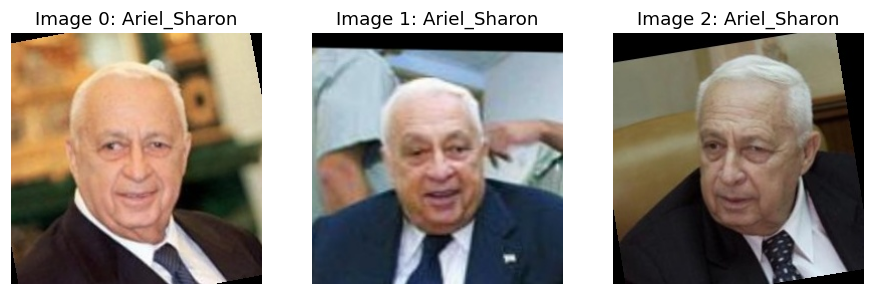

In [3]:
y = np.asarray(labels, dtype=np.int64)
shapes = {matrix.shape for matrix in image_matrices}
X = np.stack(image_matrices) if len(shapes) == 1 else image_matrices
print("X shape:", X.shape if isinstance(X, np.ndarray) else "List of original matrices with varying shapes")
print("y shape:", y.shape)
print("First image:", paths[0])
print("First matrix shape:", image_matrices[0].shape, "dtype:", image_matrices[0].dtype)
print("Top-left 3 x 3 pixels (each entry is [R, G, B]):")
print(image_matrices[0][:3, :3, :])
fig, axes = plt.subplots(1, min(3, len(image_matrices)), figsize=(10, 3), squeeze=False)
for index, ax in enumerate(axes[0]):
    ax.imshow(image_matrices[index])
    ax.set_title(f"Image {index}: {classes[y[index]]}")
    ax.axis("off")
show_figure(fig)

In [4]:
from pathlib import Path
import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display

_dimensions_root = Path.cwd()
if not (_dimensions_root / "data").is_dir():
    _dimensions_root = _dimensions_root / "analyse"
_dimensions_data = _dimensions_root / "data"
if not _dimensions_data.is_dir():
    raise FileNotFoundError("Open the notebook from the project root or analyse folder.")

_dimension_rows = []
_dimension_errors = []
for _folder in sorted(p for p in _dimensions_data.iterdir() if p.is_dir()):
    print(f"\nClass: {_folder.name}")
    print(f"{'Image':<55} {'Height':>8} {'Width':>8}")
    for _path in sorted(_folder.rglob("*")):
        if not _path.is_file() or _path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}:
            continue
        try:
            with Image.open(_path) as _image:
                # Pillow returns (width, height); apply camera orientation first.
                _width, _height = ImageOps.exif_transpose(_image).size
        except (OSError, ValueError, Image.DecompressionBombError) as _error:
            _dimension_errors.append({"path": str(_path), "error": str(_error)})
            print(f"Unreadable: {_path.name}: {_error}")
            continue
        print(f"{_path.name:<55} {_height:>8} {_width:>8}")
        _dimension_rows.append({"class": _folder.name,
                                "path": _path.relative_to(_dimensions_data).as_posix(),
                                "height": _height, "width": _width})

dimensions = pd.DataFrame(_dimension_rows, columns=["class", "path", "height", "width"])
dimension_summary = dimensions.groupby(
    ["class", "height", "width"], as_index=False
).size().rename(columns={"size": "images"})
print("\nDimension summary (pixels):")
with pd.option_context("display.max_rows", None):
    display(dimension_summary)
print(f"Total: {len(dimensions)} images; unreadable: {len(_dimension_errors)}")



Class: Ariel_Sharon
Image                                                     Height    Width
Ariel_Sharon_0001.jpg                                        250      250
Ariel_Sharon_0002.jpg                                        250      250
Ariel_Sharon_0003.jpg                                        250      250
Ariel_Sharon_0004.jpg                                        250      250
Ariel_Sharon_0005.jpg                                        250      250
Ariel_Sharon_0006.jpg                                        250      250
Ariel_Sharon_0007.jpg                                        250      250
Ariel_Sharon_0008.jpg                                        250      250
Ariel_Sharon_0009.jpg                                        250      250
Ariel_Sharon_0010.jpg                                        250      250
Ariel_Sharon_0011.jpg                                        250      250
Ariel_Sharon_0012.jpg                                        250      250
Ariel_Sharon_0013

,class,height,width,images
0,Ariel_Sharon,250,250,50
1,Colin_Powell,250,250,50
2,Donald_Rumsfeld,250,250,50
3,George_W_Bush,250,250,50
4,Gerhard_Schroeder,250,250,50
5,Hugo_Chavez,250,250,50
6,Jean_Chretien,250,250,50
7,John_Ashcroft,250,250,50
8,Junichiro_Koizumi,250,250,50
9,Tony_Blair,250,250,50


## 3. Check exact duplicates by comparing matrices
`np.array_equal(A, B)` requires identical shapes and every RGB value to match. Compare every pair, including images from different classes. No SHA-256 hash is used here. This pairwise method is suitable for this 500-image sample, but becomes expensive for large datasets.

In [5]:
pair_columns = ["path_a", "class_a", "path_b", "class_b", "cross_class"]
def pair_record(i, j):
    return {"path_a": paths[i], "class_a": classes[y[i]],
            "path_b": paths[j], "class_b": classes[y[j]],
            "cross_class": bool(y[i] != y[j])}

exact_pairs = []
for i, j in combinations(range(len(image_matrices)), 2):
    if np.array_equal(image_matrices[i], image_matrices[j]):
        exact_pairs.append((i, j))
duplicates = pd.DataFrame([pair_record(i, j) for i, j in exact_pairs], columns=pair_columns)
print("Exact duplicate pairs:", len(duplicates))
display(duplicates.head(5))

Exact duplicate pairs: 0


,path_a,class_a,path_b,class_b,cross_class


### Small matrix-comparison example
If real exact duplicates exist, show the first pair. Otherwise compare the first image with a copy and with a copy containing one changed pixel. These demonstration copies are **not added to the dataset**.

No exact duplicates in the dataset. Demonstration only:
Original vs identical copy: True
Original vs one changed RGB value: False
Original first pixel: [0 1 0] Changed first pixel: [1 1 0]


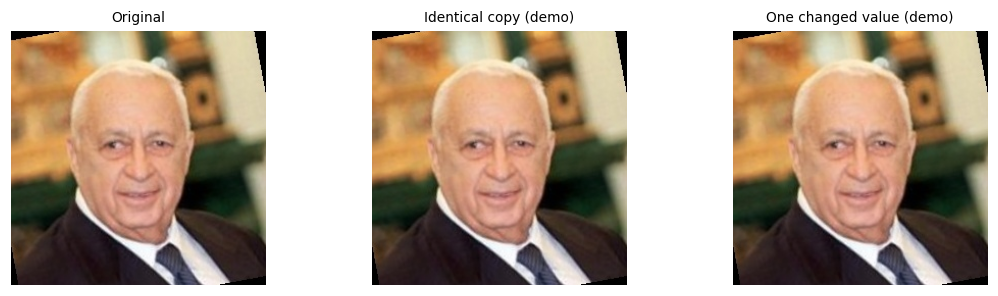

In [6]:
if exact_pairs:
    i, j = exact_pairs[0]
    example_matrices = [image_matrices[i], image_matrices[j]]
    titles = [paths[i], paths[j]]
    print("Real pair: np.array_equal =", np.array_equal(*example_matrices))
else:
    original = image_matrices[0]
    copied = original.copy()
    modified = original.copy()
    modified[0, 0, 0] = (int(modified[0, 0, 0]) + 1) % 256
    print("No exact duplicates in the dataset. Demonstration only:")
    print("Original vs identical copy:", np.array_equal(original, copied))
    print("Original vs one changed RGB value:", np.array_equal(original, modified))
    print("Original first pixel:", original[0, 0], "Changed first pixel:", modified[0, 0])
    example_matrices = [original, copied, modified]
    titles = ["Original", "Identical copy (demo)", "One changed value (demo)"]
fig, axes = plt.subplots(1, len(example_matrices), figsize=(12, 3), squeeze=False)
for ax, matrix, title in zip(axes[0], example_matrices, titles):
    ax.imshow(matrix)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
show_figure(fig)

## 4. Find near duplicates with dHash
1. Convert each original RGB matrix to grayscale.
2. Resize to **9 columns by 8 rows**.
3. Compare each value with its right neighbor: `1` if right > left, otherwise `0`.
4. Flatten the 8 x 8 comparison matrix into 64 bits.
5. Count differing bits (Hamming distance). Flag pairs with distance **at most 5**.

Exact duplicates are excluded. This checks visual resemblance, not whether two images show the same person. Adjust `THRESHOLD` and rerun from here to explore the candidates.

In [7]:
THRESHOLD = 5
if not 0 <= THRESHOLD <= 64:
    raise ValueError("THRESHOLD must be between 0 and 64.")
def dhash_steps(matrix):
    grayscale = Image.fromarray(matrix).convert("L")
    small = np.asarray(grayscale.resize((9, 8), Image.Resampling.LANCZOS))
    bits = small[:, 1:] > small[:, :-1]
    value = int.from_bytes(np.packbits(bits.ravel()).tobytes(), "big")
    return small, bits, value

hash_steps = [dhash_steps(matrix) for matrix in image_matrices]
hashes = [step[2] for step in hash_steps]
exact_set = set(exact_pairs)
near_pairs = []
for i, j in combinations(range(len(image_matrices)), 2):
    if (i, j) in exact_set:
        continue
    distance = (hashes[i] ^ hashes[j]).bit_count()
    if distance <= THRESHOLD:
        near_pairs.append((i, j, distance))
near_pairs.sort(key=lambda pair: (pair[2], paths[pair[0]], paths[pair[1]]))
near_duplicates = pd.DataFrame(
    [{**pair_record(i, j), "hamming_distance": distance} for i, j, distance in near_pairs],
    columns=pair_columns + ["hamming_distance"])
print(f"Near-duplicate candidates (distance <= {THRESHOLD}/64): {len(near_pairs)}")
display(near_duplicates.head(5))

Near-duplicate candidates (distance <= 5/64): 2


,path_a,class_a,path_b,class_b,cross_class,hamming_distance
0,George_W_Bush/George_W_Bush_0016.jpg,George_W_Bush,George_W_Bush/George_W_Bush_0039.jpg,George_W_Bush,False,5
1,George_W_Bush/George_W_Bush_0034.jpg,George_W_Bush,George_W_Bush/George_W_Bush_0036.jpg,George_W_Bush,False,5


## 5. Inspect a small near-duplicate example
Show the first candidate pair, its 9 x 8 intensity matrices, and its 64 comparison bits. Red boxes mark bits that differ. If there are no candidates, show the first image's hashing steps instead.

Candidate distance: 5 differing bits out of 64. Review visually.

 George_W_Bush/George_W_Bush_0016.jpg
9 x 8 grayscale matrix:
 [[ 37  51  74  86 102 125 141 158 169]
 [197 206 172 117 142 180 203 204 198]
 [206 197  88 108 163 166 169 193 185]
 [129 193  93 113 145 153 173 191 180]
 [ 39 190 127 123 142 172 187 186 175]
 [ 37 139  79  99 127 152 184 191 172]
 [ 55  51  41 141 140 124  94 148 171]
 [ 45  67  49 140 186 121  75  77 121]]
8 x 8 comparison matrix:
 [[1 1 1 1 1 1 1 1]
 [1 0 0 1 1 1 1 0]
 [0 0 1 1 1 1 1 0]
 [1 0 1 1 1 1 1 0]
 [1 0 0 1 1 1 0 0]
 [1 0 1 1 1 1 1 0]
 [0 0 1 0 0 0 1 1]
 [1 0 1 1 0 0 1 1]]
64-bit dHash: 1111111110011110001111101011111010011100101111100010001110110011

 George_W_Bush/George_W_Bush_0039.jpg
9 x 8 grayscale matrix:
 [[ 29  43  65  79  94 116 132 150 156]
 [194 204 176 119 142 181 205 205 199]
 [199 202  92 104 161 165 169 192 184]
 [114 195  96 111 146 153 173 191 179]
 [ 27 185 131 121 143 171 187 186 174]
 [ 27 137  81  98 127 152 183 190 171]
 [

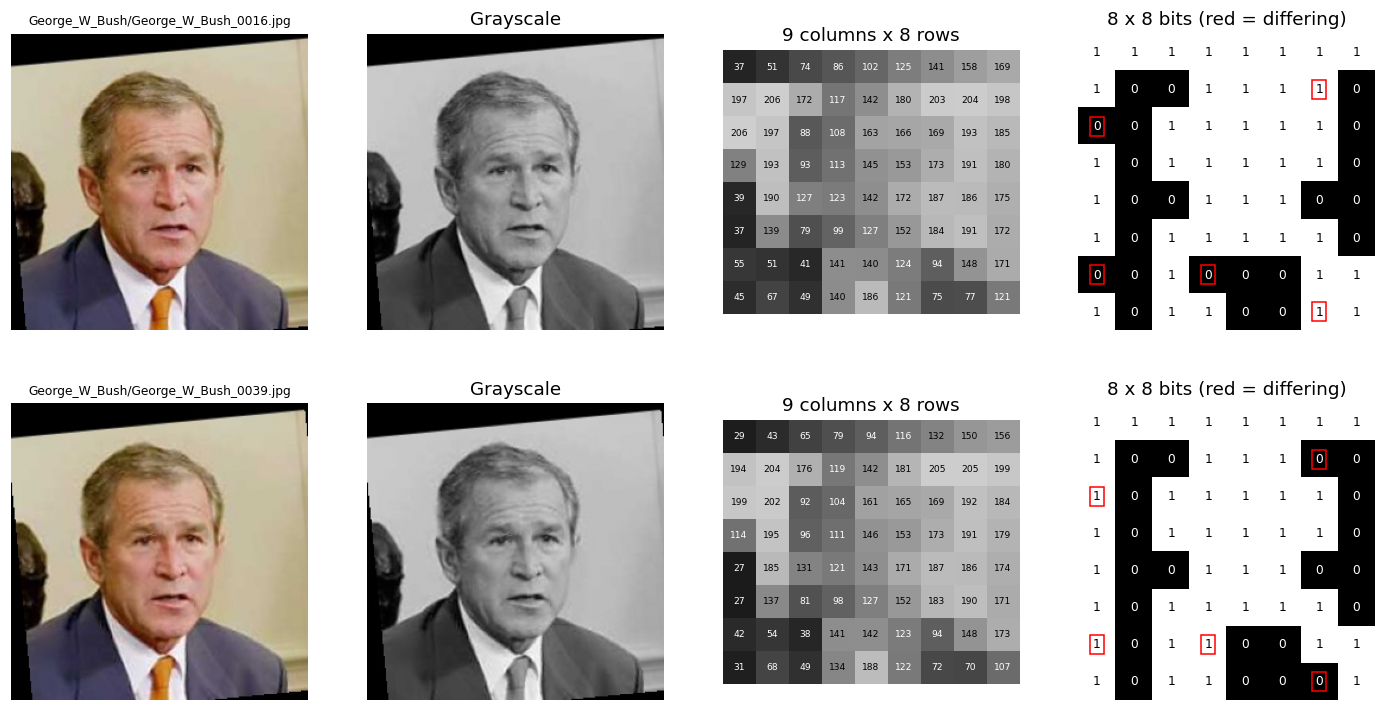

In [8]:
if near_pairs:
    i, j, distance = near_pairs[0]
    example_indices = [i, j]
    changed_bits = hash_steps[i][1] != hash_steps[j][1]
    print(f"Candidate distance: {distance} differing bits out of 64. Review visually.")
else:
    example_indices = [0]
    changed_bits = np.zeros((8, 8), dtype=bool)
    print("No near-duplicate candidates. Showing hash steps for the first image.")
fig, axes = plt.subplots(len(example_indices), 4, figsize=(16, 4 * len(example_indices)), squeeze=False)
for row, index in enumerate(example_indices):
    matrix = image_matrices[index]
    small, bits, value = hash_steps[index]
    print("\n", paths[index])
    print("9 x 8 grayscale matrix:\n", small)
    print("8 x 8 comparison matrix:\n", bits.astype(np.uint8))
    print("64-bit dHash:", f"{value:064b}")
    axes[row, 0].imshow(matrix)
    axes[row, 0].set_title(paths[index], fontsize=8)
    axes[row, 1].imshow(Image.fromarray(matrix).convert("L"), cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title("Grayscale")
    axes[row, 2].imshow(small, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[row, 2].set_title("9 columns x 8 rows")
    axes[row, 3].imshow(bits, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[row, 3].set_title("8 x 8 bits (red = differing)")
    for r in range(8):
        for c in range(9):
            axes[row, 2].text(c, r, str(small[r, c]), ha="center", va="center", fontsize=6,
                              color="black" if small[r, c] > 128 else "white")
        for c in range(8):
            axes[row, 3].text(c, r, str(int(bits[r, c])), ha="center", va="center", fontsize=8,
                              color="black" if bits[r, c] else "white",
                              bbox={"edgecolor": "red", "facecolor": "none", "pad": 2} if changed_bits[r, c] else None)
    for ax in axes[row]:
        ax.axis("off")
show_figure(fig)

## 6. Review results inside the notebook
All results are displayed here. Matrices and tables stay available as Python variables; saving the notebook retains the displayed outputs.


In [9]:
summary = pd.DataFrame([
    {"metric": "Readable images", "value": len(paths)},
    {"metric": "Classes", "value": len(classes)},
    {"metric": "Exact duplicate pairs", "value": len(exact_pairs)},
    {"metric": "Near-duplicate candidates", "value": len(near_pairs)},
    {"metric": "Unreadable images", "value": len(unreadable)},
])
display(summary)
unreadable_images = pd.DataFrame(unreadable, columns=["path", "error"])
print("Unreadable image details:")
display(unreadable_images)
hash_table = pd.DataFrame({
    "path": paths,
    "class": [classes[label] for label in y],
    "dhash_binary": [f"{value:064b}" for value in hashes],
    "dhash_hex": [f"{value:016x}" for value in hashes],
})
print("Small example of the hash table (full results are in hash_table):")
with pd.option_context("display.max_colwidth", None):
    display(hash_table.head(5))
print("Available variables: X, y, classes, paths, class_counts, dimensions, dimension_summary,")
print("duplicates, near_duplicates, unreadable_images, hash_table, summary")


Unreadable image details:
Small example of the hash table (full results are in hash_table):
Available variables: X, y, classes, paths, class_counts, dimensions, dimension_summary,
duplicates, near_duplicates, unreadable_images, hash_table, summary


,metric,value
0,Readable images,500
1,Classes,10
2,Exact duplicate pairs,0
3,Near-duplicate candidates,2
4,Unreadable images,0


,path,error


,path,class,dhash_binary,dhash_hex
0,Ariel_Sharon/Ariel_Sharon_0001.jpg,Ariel_Sharon,1110011001100011111100111001000101100001011000110011000100011100,e663f3916163311c
1,Ariel_Sharon/Ariel_Sharon_0002.jpg,Ariel_Sharon,1001001110010011100100110111001001101010001100010010101001101010,939393726a312a6a
2,Ariel_Sharon/Ariel_Sharon_0003.jpg,Ariel_Sharon,1111110010110000001101001101010000110000001101000001110010011110,fcb034d430341c9e
3,Ariel_Sharon/Ariel_Sharon_0004.jpg,Ariel_Sharon,0001100010110000001101000011001100110010010011000100100000011010,18b03433324c481a
4,Ariel_Sharon/Ariel_Sharon_0005.jpg,Ariel_Sharon,0011001011111000111101001001011010110001001110011011100100111001,32f8f496b139b939


## 7. Image quality EDA on preprocessed_data
Analyze the manually cleaned dataset at its original resolution. All measurements describe the **whole image**, including background, rather than just the face. No images are altered or automatically removed.

| Metric | Calculation |
| --- | --- |
| Brightness | Mean 8-bit grayscale intensity (0?255) |
| Contrast | Population standard deviation of grayscale intensities |
| Sharpness | Variance of the grayscale Laplacian (`CV_64F`, kernel size 1); lower values are candidates for blur |
| Underexposure | Fraction of grayscale pixels **<= 5** |
| Overexposure | Fraction of grayscale pixels **>= 250** |
| RGB channel means | Mean of each original R, G, B channel |
| Color variation | Population standard deviation of each R, G, B channel |
| Entropy | Shannon entropy `-sum(p * log2(p))` of the 256-bin grayscale histogram (0?8 bits) |
| Edge density | Fraction of nonzero Canny edge pixels, thresholds **100/200**, after a 3 ? 3 Gaussian blur (sigma 0) |

Exposure and edge thresholds are configurable in the next cell. Laplacian variance is affected by texture, noise, and image resolution, so the blurriest gallery ranks this measure rather than proving optical blur. Class boxplots include all measurements; gallery categories can overlap.

References: [OpenCV Laplacian](https://docs.opencv.org/4.x/d5/db5/tutorial_laplace_operator.html), [OpenCV Canny](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html).

In [10]:
from pathlib import Path
import io
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Image as DisplayImage

QUALITY_BASE = Path.cwd()
if not (QUALITY_BASE / "preprocessed_data").is_dir():
    QUALITY_BASE = QUALITY_BASE / "analyse"
QUALITY_DATA = QUALITY_BASE / "preprocessed_data"
if not QUALITY_DATA.is_dir():
    raise FileNotFoundError(f"Missing cleaned dataset: {QUALITY_DATA.resolve()}")
QUALITY_RESULTS = QUALITY_DATA / "quality_results"
QUALITY_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
QUALITY_REPORT_FOLDERS = {"mtcnn_results", "quality_results"}
DARK_THRESHOLD, BRIGHT_THRESHOLD = 5, 250
CANNY_LOW, CANNY_HIGH = 100, 200
if not 0 <= DARK_THRESHOLD < BRIGHT_THRESHOLD <= 255:
    raise ValueError("Exposure thresholds must satisfy 0 <= dark < bright <= 255.")
if not 0 <= CANNY_LOW < CANNY_HIGH:
    raise ValueError("Canny thresholds must satisfy 0 <= low < high.")

def quality_show(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(DisplayImage(data=buffer.getvalue()))

print("Quality input:", QUALITY_DATA.resolve())
print("Exposure thresholds:", DARK_THRESHOLD, BRIGHT_THRESHOLD)
print("Canny thresholds:", CANNY_LOW, CANNY_HIGH)

Quality input: C:\Users\Anas Karim\Desktop\face-recognition\analyse\preprocessed_data
Exposure thresholds: 5 250
Canny thresholds: 100 200


### Compute the metrics for every cleaned image
RGB is explicitly converted with `COLOR_RGB2GRAY` (Pillow loads RGB). Unreadable images are reported separately. The full results table is available as `quality_metrics`.

In [11]:
def image_quality_metrics(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    histogram = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    probabilities = histogram[histogram > 0] / gray.size
    channel_means = rgb.mean(axis=(0, 1))
    channel_stds = rgb.std(axis=(0, 1), ddof=0)
    edge_input = cv2.GaussianBlur(gray, (3, 3), 0)
    edges = cv2.Canny(edge_input, CANNY_LOW, CANNY_HIGH)
    return {
        "brightness": float(gray.mean()),
        "contrast": float(gray.std(ddof=0)),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F, ksize=1).var(ddof=0)),
        "underexposure_fraction": float(np.mean(gray <= DARK_THRESHOLD)),
        "overexposure_fraction": float(np.mean(gray >= BRIGHT_THRESHOLD)),
        "mean_r": float(channel_means[0]), "mean_g": float(channel_means[1]),
        "mean_b": float(channel_means[2]),
        "std_r": float(channel_stds[0]), "std_g": float(channel_stds[1]),
        "std_b": float(channel_stds[2]),
        "entropy_bits": float(-np.sum(probabilities * np.log2(probabilities))),
        "edge_density": float(np.count_nonzero(edges) / gray.size),
    }

quality_rows, quality_errors = [], []
for folder in sorted(p for p in QUALITY_DATA.iterdir()
                     if p.is_dir() and p.name not in QUALITY_REPORT_FOLDERS):
    for image_path in sorted(folder.rglob("*")):
        if not image_path.is_file() or image_path.suffix.lower() not in QUALITY_EXTENSIONS:
            continue
        relative = image_path.relative_to(QUALITY_DATA).as_posix()
        try:
            with Image.open(image_path) as source:
                rgb = np.array(ImageOps.exif_transpose(source).convert("RGB"))
            quality_rows.append({"class": folder.name, "path": relative,
                                 "height": rgb.shape[0], "width": rgb.shape[1],
                                 **image_quality_metrics(rgb)})
        except (OSError, ValueError, cv2.error, Image.DecompressionBombError) as error:
            quality_errors.append({"class": folder.name, "path": relative, "error": str(error)})
if not quality_rows:
    raise ValueError("No readable images in preprocessed_data.")
quality_metrics = pd.DataFrame(quality_rows).sort_values(["class", "path"]).reset_index(drop=True)
quality_unreadable = pd.DataFrame(quality_errors, columns=["class", "path", "error"])
quality_class_counts = quality_metrics.groupby("class").size().rename("images").reset_index()
print(f"Measured {len(quality_metrics)} images in {len(quality_class_counts)} classes.")
print("Unreadable images:", len(quality_unreadable))
display(quality_class_counts)
with pd.option_context("display.max_columns", None):
    display(quality_metrics.head(5))
    display(quality_metrics.select_dtypes(include=np.number).describe().T)
if not quality_unreadable.empty:
    display(quality_unreadable)

Measured 499 images in 10 classes.
Unreadable images: 0


,class,images
0,Ariel_Sharon,50
1,Colin_Powell,50
2,Donald_Rumsfeld,50
3,George_W_Bush,49
4,Gerhard_Schroeder,50
5,Hugo_Chavez,50
6,Jean_Chretien,50
7,John_Ashcroft,50
8,Junichiro_Koizumi,50
9,Tony_Blair,50


,class,path,height,width,brightness,contrast,sharpness,underexposure_fraction,overexposure_fraction,mean_r,mean_g,mean_b,std_r,std_g,std_b,entropy_bits,edge_density
0,Ariel_Sharon,Ariel_Sharon/Ariel_Sharon_0001.jpg,250,250,123.118352,69.175152,351.795802,0.023872,0.001568,145.905264,117.688864,91.163632,82.065949,66.736332,58.406817,7.682982,0.020848
1,Ariel_Sharon,Ariel_Sharon/Ariel_Sharon_0002.jpg,250,250,118.209088,70.600012,64.364530,0.062720,0.001232,116.904832,117.904960,123.183184,74.835958,70.563051,70.051135,7.309178,0.031376
2,Ariel_Sharon,Ariel_Sharon/Ariel_Sharon_0003.jpg,250,250,86.766848,62.683394,304.664551,0.108768,0.000000,94.662592,85.272768,73.827280,65.631031,62.924490,57.893606,7.093794,0.030112
3,Ariel_Sharon,Ariel_Sharon/Ariel_Sharon_0004.jpg,250,250,106.806736,70.652300,189.427203,0.098832,0.022640,116.175840,104.938320,91.894048,71.935925,71.183226,69.812556,7.466649,0.067152
4,Ariel_Sharon,Ariel_Sharon/Ariel_Sharon_0005.jpg,250,250,109.537920,59.471879,214.689300,0.047696,0.000128,118.243328,108.350784,92.746608,62.938627,59.603768,59.280146,7.399691,0.032912


,count,mean,std,min,25%,50%,75%,max
height,499.0,250.000000,0.000000,250.000000,250.000000,250.000000,250.000000,250.000000
width,499.0,250.000000,0.000000,250.000000,250.000000,250.000000,250.000000,250.000000
brightness,499.0,98.793862,26.908566,27.214112,79.887080,96.409056,117.299264,181.106544
contrast,499.0,64.245339,10.198389,36.571709,57.053733,63.662247,70.657357,99.825756
sharpness,499.0,299.198693,235.521139,14.643183,125.325309,230.045836,385.265313,1221.872752
underexposure_fraction,499.0,0.097151,0.089997,0.000000,0.031616,0.077600,0.133064,0.578480
overexposure_fraction,499.0,0.013182,0.042735,0.000000,0.000000,0.002128,0.009336,0.497120
mean_r,499.0,109.234637,28.031830,39.704160,88.980496,107.937872,127.563872,200.841504
mean_g,499.0,96.021676,27.590058,23.016624,75.759520,92.829536,114.925016,178.331696
mean_b,499.0,85.651353,28.765101,16.126976,64.343248,83.921552,104.359608,179.448608


### Histograms and class boxplots
The top row shows overall distributions; the bottom row compares classes for brightness, contrast, and sharpness. Boxplot points beyond whiskers are statistical outliers, not automatic removal decisions.

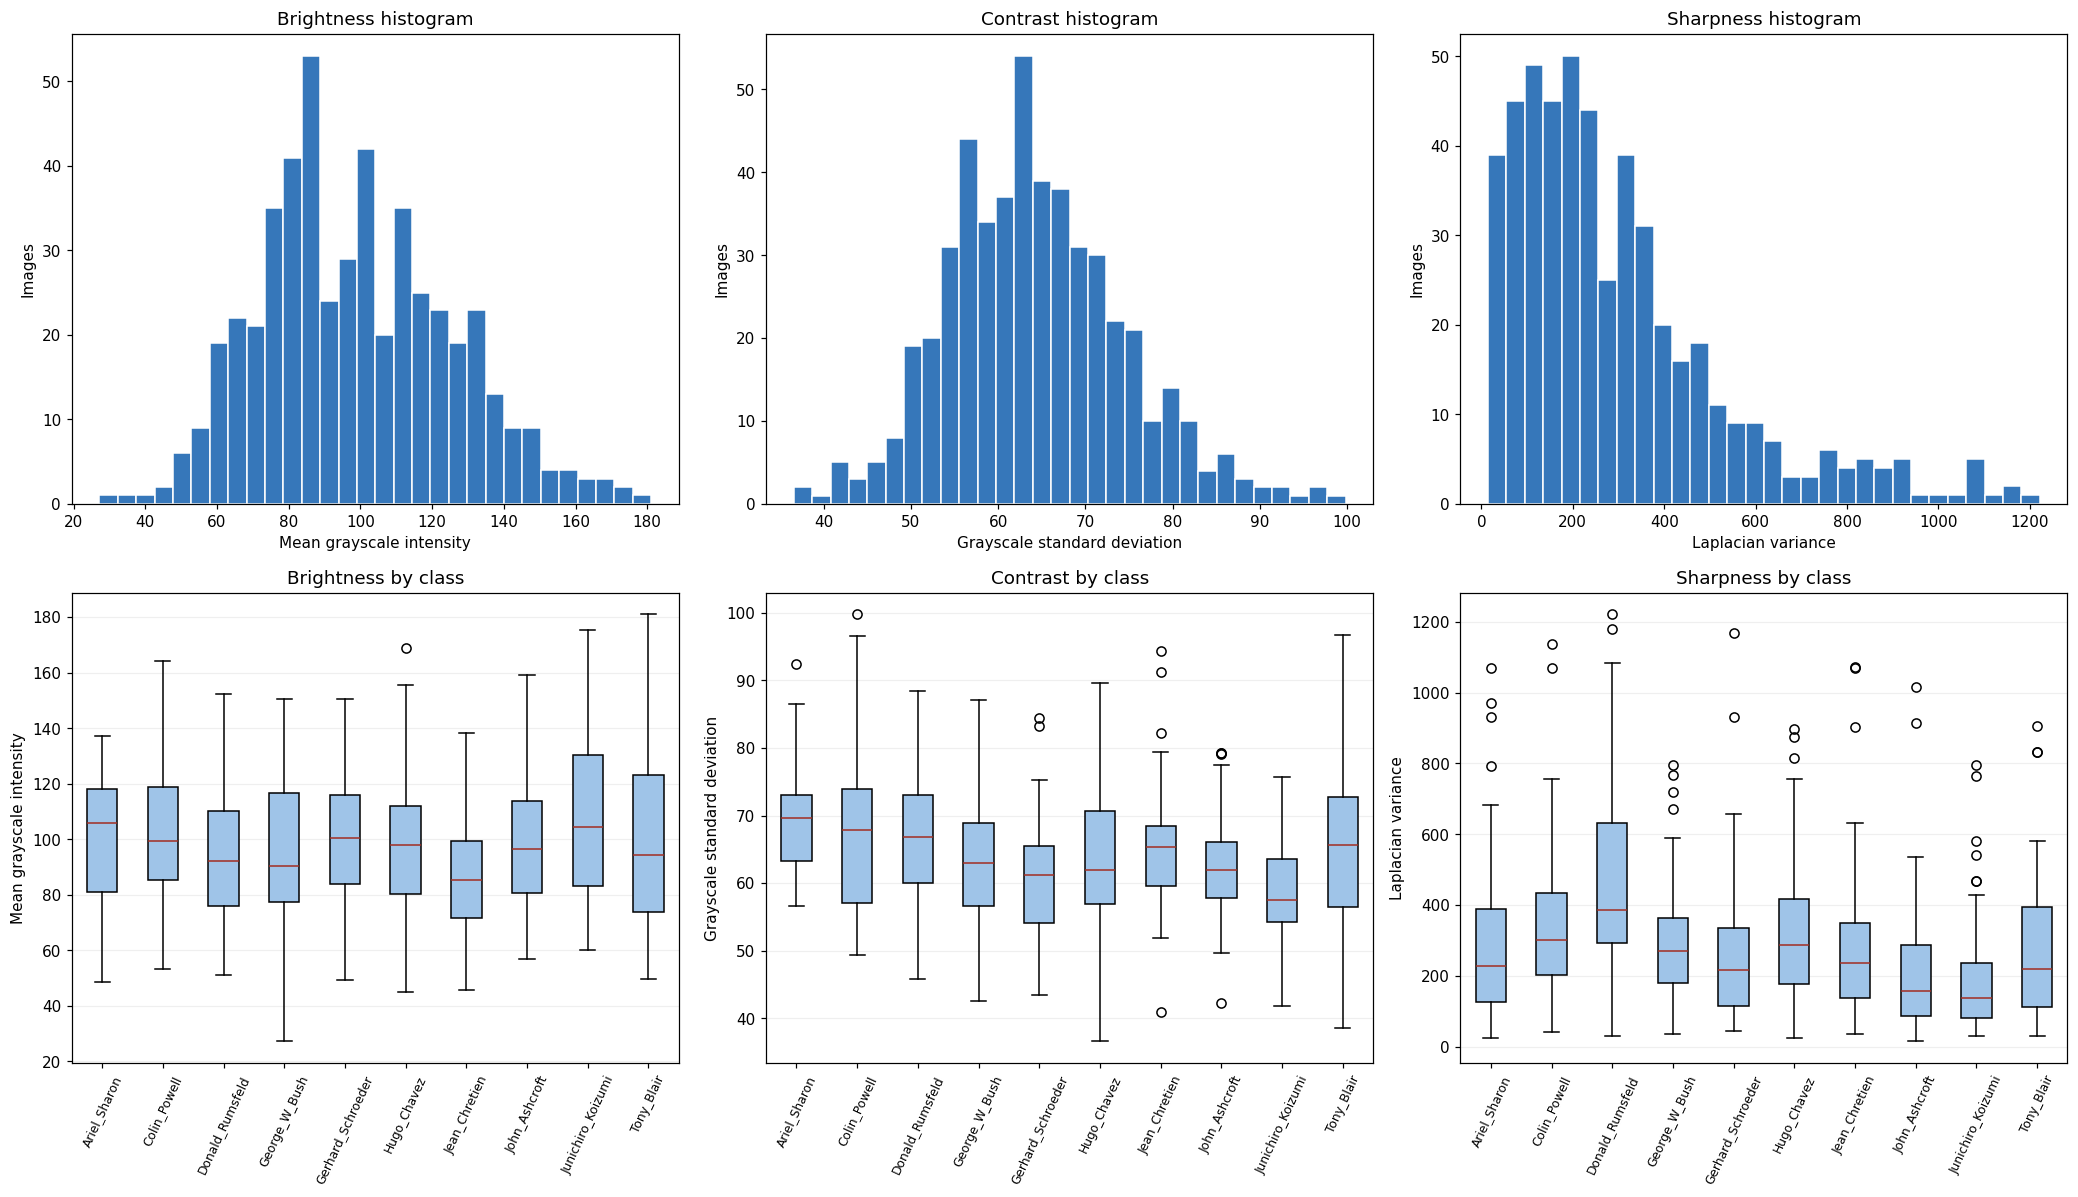

In [12]:
quality_plot_columns = ["brightness", "contrast", "sharpness"]
quality_axis_labels = ["Mean grayscale intensity", "Grayscale standard deviation", "Laplacian variance"]
quality_class_names = quality_class_counts["class"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
for column, metric, label in zip(range(3), quality_plot_columns, quality_axis_labels):
    axes[0, column].hist(quality_metrics[metric], bins=30, color="#3677ba", edgecolor="white")
    axes[0, column].set_title(f"{metric.title()} histogram")
    axes[0, column].set_xlabel(label)
    axes[0, column].set_ylabel("Images")
    grouped_values = [quality_metrics.loc[quality_metrics["class"] == name, metric].to_numpy()
                      for name in quality_class_names]
    axes[1, column].boxplot(grouped_values, tick_labels=quality_class_names, patch_artist=True,
                           boxprops={"facecolor": "#9fc4e8"}, medianprops={"color": "#a22d22"})
    axes[1, column].set_title(f"{metric.title()} by class")
    axes[1, column].set_ylabel(label)
    axes[1, column].tick_params(axis="x", labelrotation=65, labelsize=8)
    axes[1, column].grid(axis="y", alpha=0.2)
fig.tight_layout()
quality_show(fig)

### Brightness versus contrast and sharpness
Each point is an image, colored by its class. These plots describe associations, not causal effects.

Pearson correlations (descriptive):


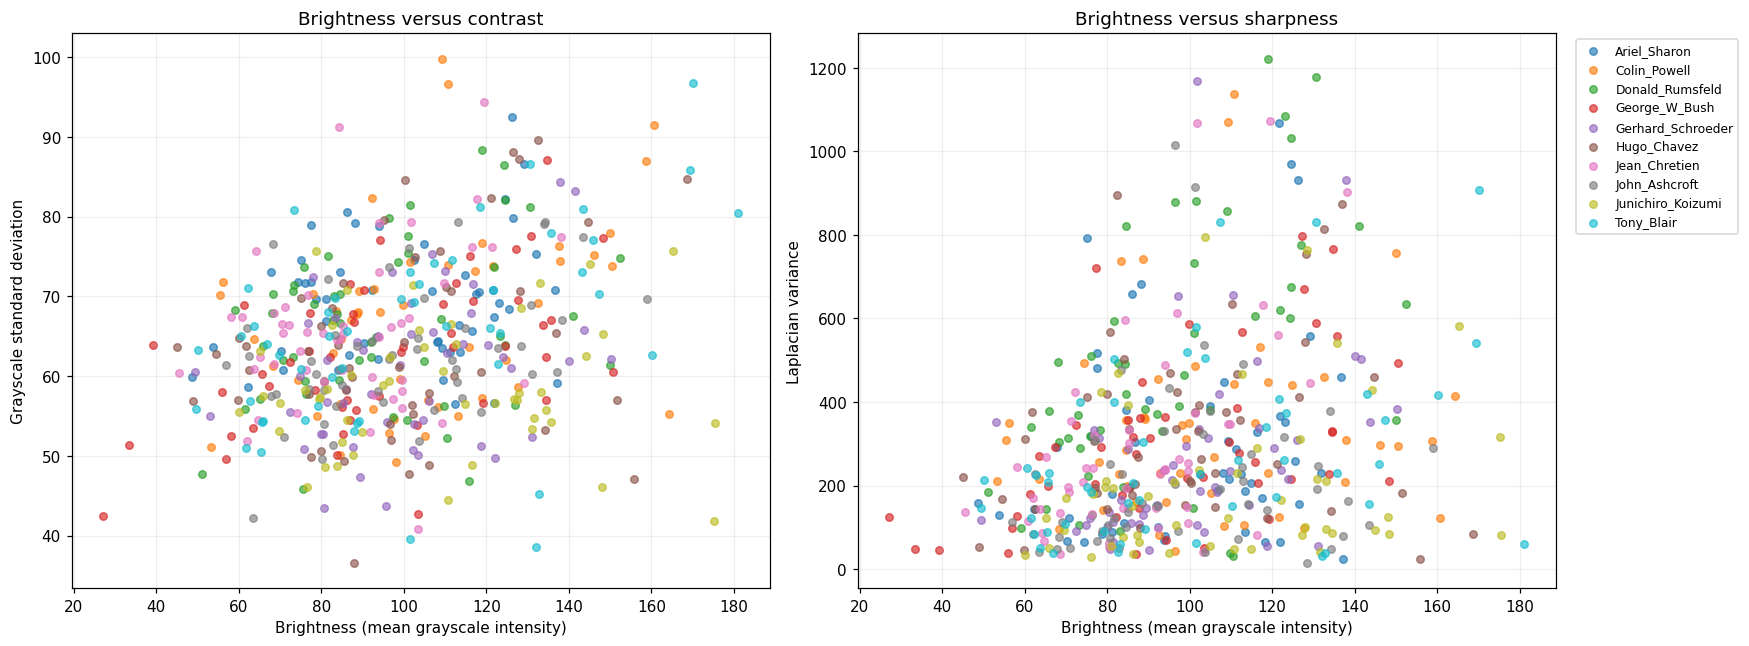

,brightness,contrast,sharpness
brightness,1.000000,0.295093,0.272404
contrast,0.295093,1.000000,0.526781
sharpness,0.272404,0.526781,1.000000


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = plt.get_cmap("tab10")
for index, class_name in enumerate(quality_class_names):
    group = quality_metrics.loc[quality_metrics["class"] == class_name]
    for ax, metric in zip(axes, ["contrast", "sharpness"]):
        ax.scatter(group["brightness"], group[metric], color=colors(index % 10),
                   label=class_name, alpha=0.65, s=24)
for ax, metric, label in zip(axes, ["contrast", "sharpness"], quality_axis_labels[1:]):
    ax.set_xlabel("Brightness (mean grayscale intensity)")
    ax.set_ylabel(label)
    ax.set_title(f"Brightness versus {metric}")
    ax.grid(alpha=0.2)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
fig.tight_layout()
quality_show(fig)
print("Pearson correlations (descriptive):")
display(quality_metrics[quality_plot_columns].corr())

### Five darkest, brightest, blurriest, and lowest-contrast images
Rank images by the specified metric. Blurriest means the five lowest Laplacian variances. Every thumbnail includes the class, filename, and score. Original colors and intensity ranges are preserved. Images can appear in multiple categories.

Five darkest
Five brightest
Five blurriest (lowest Laplacian variance)
Five lowest-contrast


,class,path,brightness,contrast,sharpness
0,George_W_Bush,George_W_Bush/George_W_Bush_0023.jpg,27.214112,42.482361,124.551309
1,George_W_Bush,George_W_Bush/George_W_Bush_0027.jpg,33.447232,51.322821,47.663298
2,George_W_Bush,George_W_Bush/George_W_Bush_0032.jpg,39.228512,63.854311,46.746004
3,Hugo_Chavez,Hugo_Chavez/Hugo_Chavez_0040.jpg,45.002064,63.650234,221.399952
4,Jean_Chretien,Jean_Chretien/Jean_Chretien_0034.jpg,45.633008,60.337432,136.110576


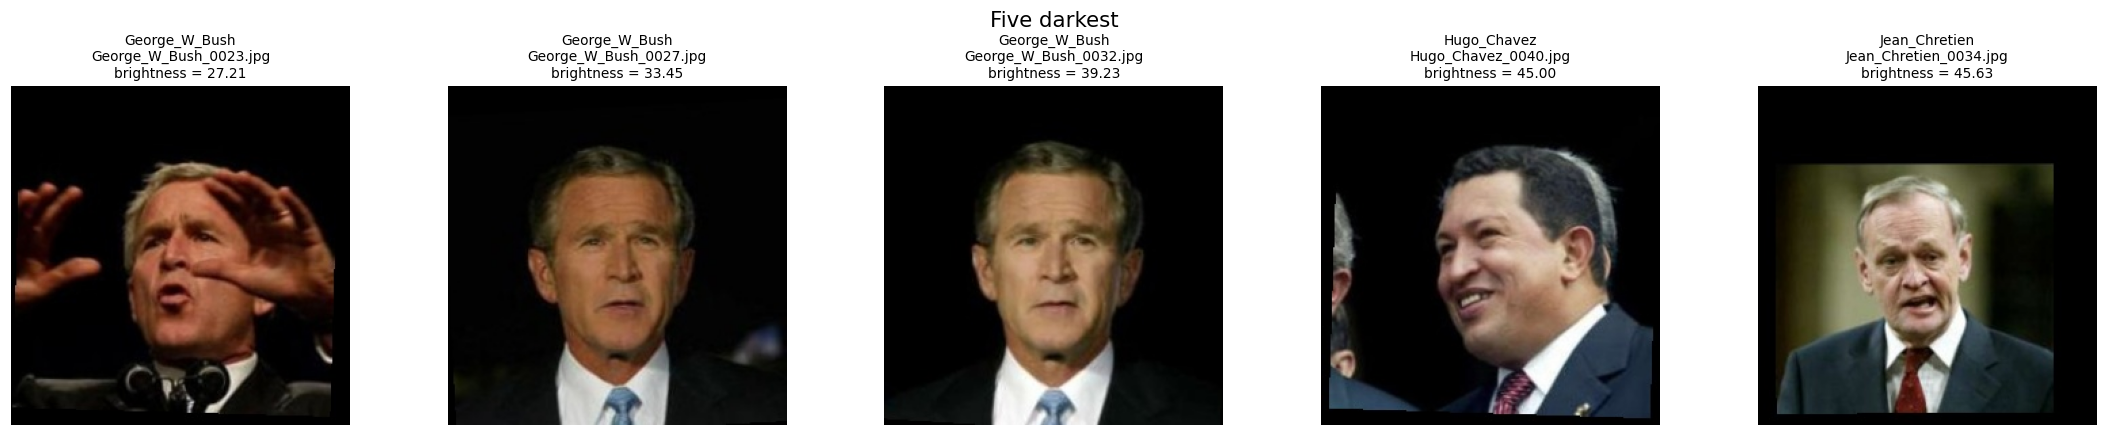

,class,path,brightness,contrast,sharpness
0,Tony_Blair,Tony_Blair/Tony_Blair_0019.jpg,181.106544,80.503737,58.958862
1,Junichiro_Koizumi,Junichiro_Koizumi/Junichiro_Koizumi_0035.jpg,175.503728,54.179021,82.684179
2,Junichiro_Koizumi,Junichiro_Koizumi/Junichiro_Koizumi_0033.jpg,175.189680,41.785392,316.235088
3,Tony_Blair,Tony_Blair/Tony_Blair_0010.jpg,170.182368,96.704317,906.339679
4,Tony_Blair,Tony_Blair/Tony_Blair_0013.jpg,169.280800,85.840773,540.231058


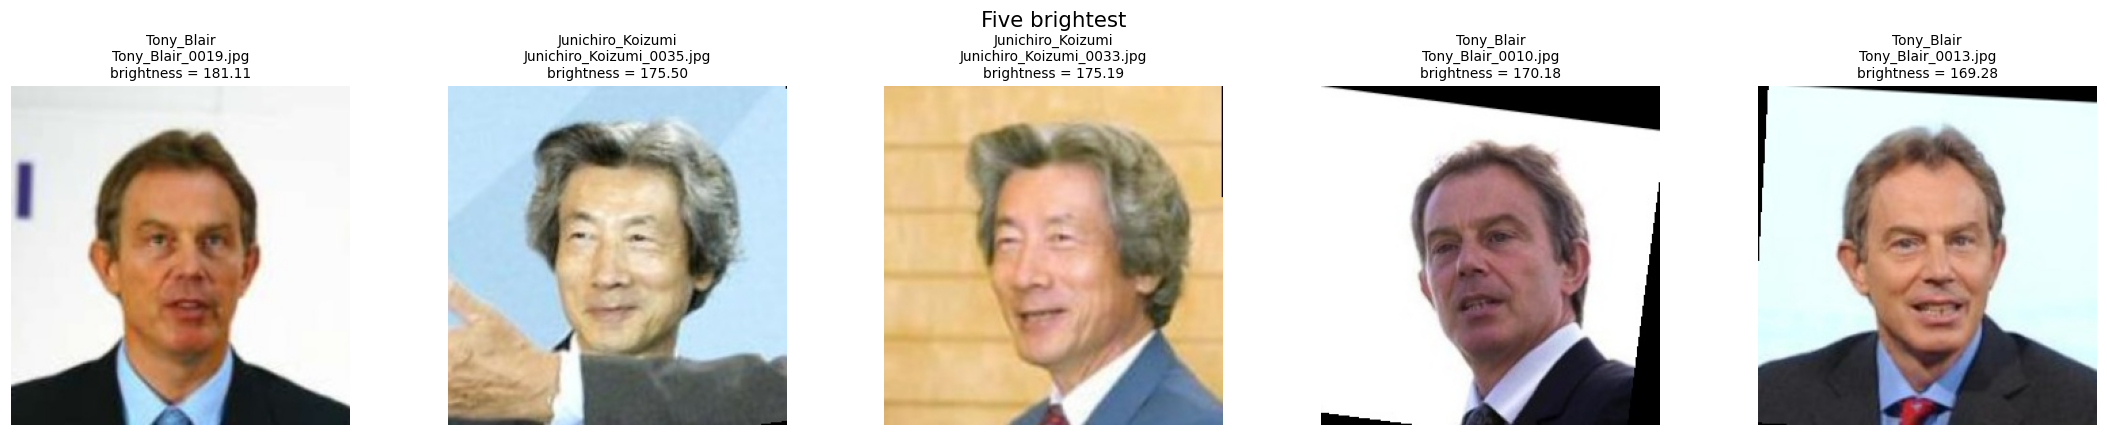

,class,path,brightness,contrast,sharpness
0,John_Ashcroft,John_Ashcroft/John_Ashcroft_0043.jpg,128.413536,63.831858,14.643183
1,Ariel_Sharon,Ariel_Sharon/Ariel_Sharon_0048.jpg,137.122224,59.151025,24.197955
2,Hugo_Chavez,Hugo_Chavez/Hugo_Chavez_0021.jpg,155.707728,47.156312,24.965747
3,Junichiro_Koizumi,Junichiro_Koizumi/Junichiro_Koizumi_0018.jpg,76.110208,58.204357,29.438063
4,Tony_Blair,Tony_Blair/Tony_Blair_0029.jpg,132.105440,38.561813,30.802117


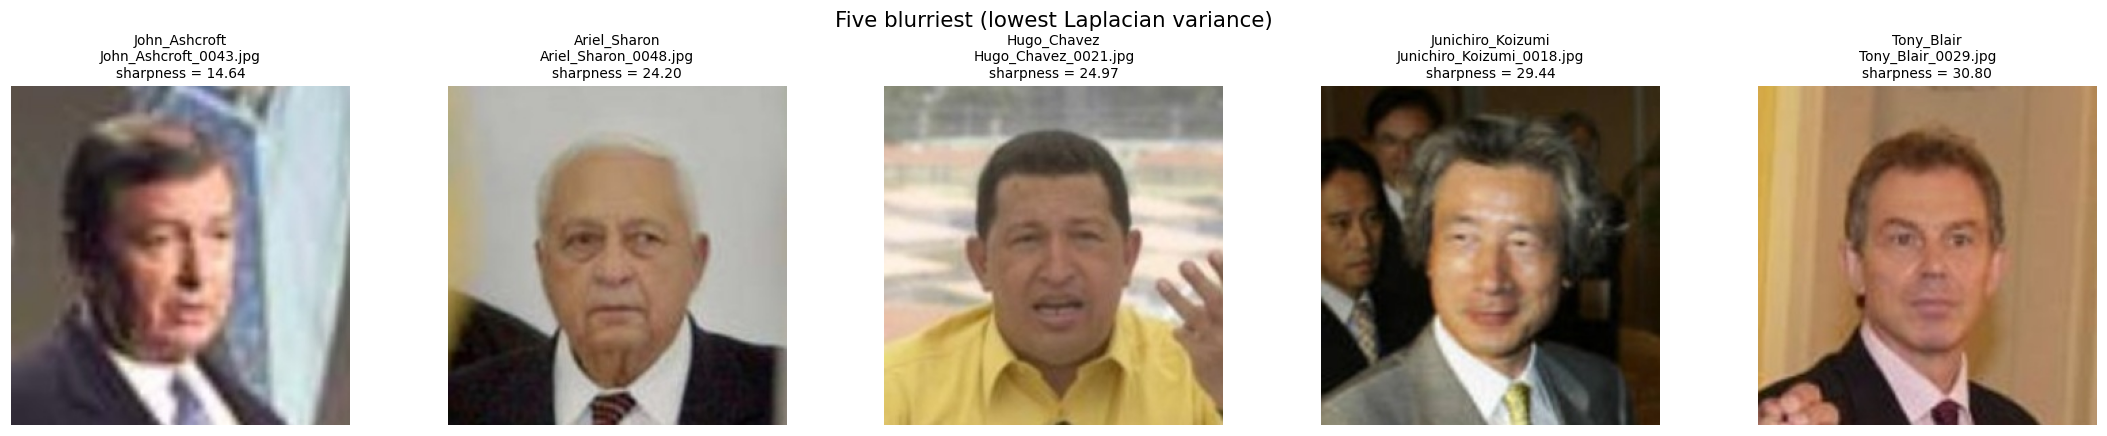

,class,path,brightness,contrast,sharpness
0,Hugo_Chavez,Hugo_Chavez/Hugo_Chavez_0001.jpg,87.996160,36.571709,97.203748
1,Tony_Blair,Tony_Blair/Tony_Blair_0029.jpg,132.105440,38.561813,30.802117
2,Tony_Blair,Tony_Blair/Tony_Blair_0022.jpg,101.430928,39.545821,63.272480
3,Jean_Chretien,Jean_Chretien/Jean_Chretien_0004.jpg,103.321600,40.878299,39.715077
4,Junichiro_Koizumi,Junichiro_Koizumi/Junichiro_Koizumi_0033.jpg,175.189680,41.785392,316.235088


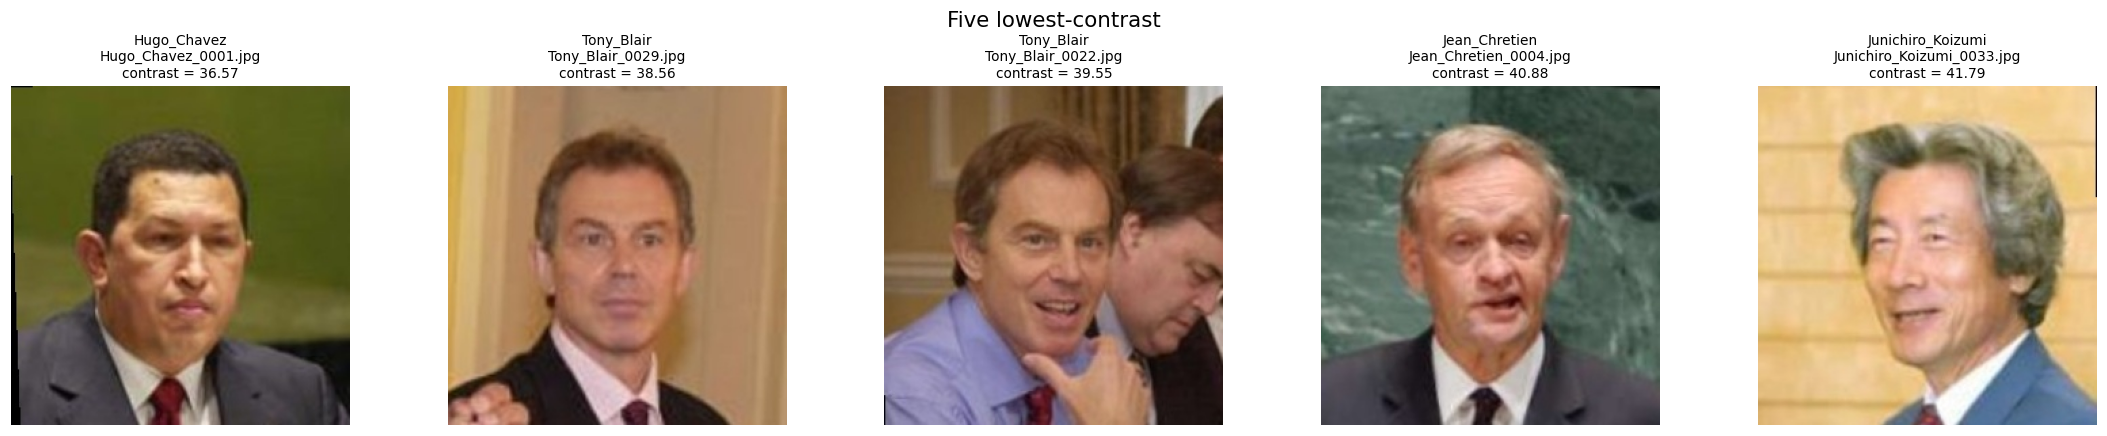

In [14]:
quality_rankings = [
    ("Five darkest", "brightness", True),
    ("Five brightest", "brightness", False),
    ("Five blurriest (lowest Laplacian variance)", "sharpness", True),
    ("Five lowest-contrast", "contrast", True),
]
quality_extreme_rows = []
for title, metric, ascending in quality_rankings:
    selected = quality_metrics.sort_values([metric, "path"], ascending=[ascending, True]).head(5)
    print(title)
    display(selected[["class", "path", "brightness", "contrast", "sharpness"]].reset_index(drop=True))
    fig, axes = plt.subplots(1, len(selected), figsize=(4 * len(selected), 4), squeeze=False)
    fig.suptitle(title, fontsize=14)
    for rank, (ax, (_, row)) in enumerate(zip(axes[0], selected.iterrows()), start=1):
        with Image.open(QUALITY_DATA / row["path"]) as source:
            ax.imshow(ImageOps.exif_transpose(source).convert("RGB"))
        ax.set_title(f"{row['class']}\n{Path(row['path']).name}\n{metric} = {row[metric]:.2f}", fontsize=9)
        ax.axis("off")
        quality_extreme_rows.append({"category": title, "rank": rank, **row.to_dict()})
    fig.tight_layout()
    quality_show(fig)
quality_extremes = pd.DataFrame(quality_extreme_rows)

### Save metrics beside the cleaned dataset
All tables and plots are displayed inline above. CSV measurements, selected extremes, and calculation settings are also saved under `preprocessed_data/quality_results`; class images stay intact.

In [15]:
import json
QUALITY_RESULTS.mkdir(parents=True, exist_ok=True)
quality_metrics.to_csv(QUALITY_RESULTS / "image_quality.csv", index=False)
quality_metrics.groupby("class")[quality_plot_columns].agg(["count", "mean", "std", "min", "median", "max"]).to_csv(
    QUALITY_RESULTS / "class_summary.csv")
quality_unreadable.to_csv(QUALITY_RESULTS / "unreadable.csv", index=False)
quality_extremes.to_csv(QUALITY_RESULTS / "extreme_images.csv", index=False)
quality_settings = {
    "dataset": str(QUALITY_DATA.resolve()), "scope": "whole image, EXIF orientation corrected, original resolution",
    "grayscale": "cv2.COLOR_RGB2GRAY, uint8", "std_ddof": 0,
    "dark_threshold_inclusive": DARK_THRESHOLD, "bright_threshold_inclusive": BRIGHT_THRESHOLD,
    "laplacian_depth": "CV_64F", "laplacian_ksize": 1,
    "edge_gaussian_kernel": [3, 3], "edge_gaussian_sigma": 0,
    "canny_thresholds": [CANNY_LOW, CANNY_HIGH], "entropy_bins": 256, "entropy_log_base": 2,
    "opencv_version": cv2.__version__, "readable_images": len(quality_metrics),
}
(QUALITY_RESULTS / "settings.json").write_text(json.dumps(quality_settings, indent=2) + "\n", encoding="utf-8")
print("Saved image-quality measurements to", QUALITY_RESULTS.resolve())

Saved image-quality measurements to C:\Users\Anas Karim\Desktop\face-recognition\analyse\preprocessed_data\quality_results


## 8. MTCNN face detection on preprocessed_data
This section runs independently of the earlier EDA cells. Read the manually cleaned class folders in `analyse/preprocessed_data`. Images are left intact. Save measurements in `preprocessed_data/mtcnn_results`.

- **Confidence:** MTCNN's detection score, not a calibrated probability of correct identity.
- **Box:** raw detector `(x, y, width, height)` plus the box clipped to the image boundaries. Area ratio uses the clipped box area divided by image area, not a segmented face area.
- **Position:** clipped box center in pixels and normalized coordinates (0 = left/top, 1 = right/bottom), plus offset from the image center.
- **Eye angle:** eye line in degrees from horizontal, with eyes ordered by screen x coordinate. Positive means the line slopes downward to the right; missing or coincident eyes produce NaN. This measures in-plane rotation, not head yaw or pitch.
- **Landmarks:** availability and image-boundary validity of both eyes, nose, and both mouth corners. Availability does not establish accuracy.

All returned detections are retained. Images with no face or read/detection errors are explicitly recorded. The highest-confidence detection is marked as the primary face; it is not guaranteed to be the labeled person.

API reference: https://mtcnn.readthedocs.io/en/latest/usage_params/

In [16]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display

MTCNN_BASE = Path.cwd()
if not (MTCNN_BASE / "preprocessed_data").is_dir():
    MTCNN_BASE = MTCNN_BASE / "analyse"
MTCNN_DATA = MTCNN_BASE / "preprocessed_data"
if not MTCNN_DATA.is_dir():
    raise FileNotFoundError(f"Missing dataset: {MTCNN_DATA.resolve()}")
MTCNN_RESULTS = MTCNN_DATA / "mtcnn_results"
MTCNN_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
LANDMARKS = ("left_eye", "right_eye", "nose", "mouth_left", "mouth_right")
print("Input:", MTCNN_DATA.resolve())
print("Results:", MTCNN_RESULTS.resolve())

Input: C:\Users\Anas Karim\Desktop\face-recognition\analyse\preprocessed_data
Results: C:\Users\Anas Karim\Desktop\face-recognition\analyse\preprocessed_data\mtcnn_results


### Measure each detection
The following helper contains the measurement logic and can be run without TensorFlow.

In [17]:
def measure_face(face, image_width, image_height):
    x, y, width, height = map(float, face["box"])
    x1 = float(np.clip(x, 0, image_width))
    y1 = float(np.clip(y, 0, image_height))
    x2 = float(np.clip(x + width, 0, image_width))
    y2 = float(np.clip(y + height, 0, image_height))
    clipped_width, clipped_height = max(0.0, x2 - x1), max(0.0, y2 - y1)
    valid_box = clipped_width > 0 and clipped_height > 0
    cx, cy = ((x1 + x2) / 2, (y1 + y2) / 2) if valid_box else (np.nan, np.nan)
    result = {
        "confidence": float(face["confidence"]),
        "bbox_x": x, "bbox_y": y, "bbox_width": width, "bbox_height": height,
        "bbox_area": max(0.0, width) * max(0.0, height),
        "clipped_x": x1, "clipped_y": y1,
        "clipped_width": clipped_width, "clipped_height": clipped_height,
        "valid_box": valid_box,
        "box_was_clipped": (x1, y1, x2, y2) != (x, y, x + width, y + height),
        "face_to_image_area_ratio": clipped_width * clipped_height / (image_width * image_height),
        "face_center_x": cx, "face_center_y": cy,
        "face_center_x_normalized": cx / image_width,
        "face_center_y_normalized": cy / image_height,
        "face_offset_x_normalized": cx / image_width - 0.5,
        "face_offset_y_normalized": cy / image_height - 0.5,
    }
    points = face.get("keypoints") or {}
    available_points = {}
    for name in LANDMARKS:
        point = points.get(name)
        available = point is not None and len(point) == 2 and bool(np.isfinite(point).all())
        px, py = map(float, point) if available else (np.nan, np.nan)
        in_image = available and 0 <= px < image_width and 0 <= py < image_height
        result.update({f"{name}_available": available, f"{name}_in_image": bool(in_image),
                       f"{name}_x": px, f"{name}_y": py})
        if available:
            available_points[name] = (px, py)
    result["landmarks_available_count"] = len(available_points)
    result["all_landmarks_available"] = len(available_points) == len(LANDMARKS)
    result["all_landmarks_in_image"] = all(result[f"{name}_in_image"] for name in LANDMARKS)
    result["eye_angle_degrees"] = np.nan
    if "left_eye" in available_points and "right_eye" in available_points:
        left, right = sorted([available_points["left_eye"], available_points["right_eye"]])
        dx, dy = right[0] - left[0], right[1] - left[1]
        if math.hypot(dx, dy) > 0:
            result["eye_angle_degrees"] = math.degrees(math.atan2(dy, dx))
    result["eye_angle_available"] = bool(np.isfinite(result["eye_angle_degrees"]))
    result["eye_angle_abs_degrees"] = abs(result["eye_angle_degrees"])
    return result

### Run the detector and save measurements
This cell requires a working TensorFlow/MTCNN installation. On this computer, the TensorFlow DLL was blocked by Windows Application Control during verification. Use an organization-approved Python environment or ask IT to allow the dependency before running this cell. No detection results are fabricated when initialization fails.

In [18]:
# Initialize before writing results, so a runtime failure cannot replace valid reports.
try:
    from mtcnn import MTCNN
    mtcnn_detector = MTCNN()
except Exception as error:
    raise RuntimeError(
        "MTCNN could not initialize. If TensorFlow reports an Application Control/DLL block, "
        "use an approved environment or contact IT. No detection reports were written."
    ) from error

mtcnn_files = []
for folder in sorted(MTCNN_DATA.iterdir()):
    if folder.is_dir() and folder.name not in {"mtcnn_results", "quality_results"}:
        mtcnn_files.extend((folder.name, p) for p in sorted(folder.rglob("*"))
                           if p.is_file() and p.suffix.lower() in MTCNN_EXTENSIONS)
if not mtcnn_files:
    raise ValueError("No images found in preprocessed_data class folders.")

mtcnn_detection_rows, mtcnn_image_rows = [], []
for index, (class_name, image_path) in enumerate(mtcnn_files, start=1):
    relative_path = image_path.relative_to(MTCNN_DATA).as_posix()
    status = {"path": relative_path, "class": class_name,
              "image_width": None, "image_height": None,
              "status": "ok", "detections": 0, "max_confidence": np.nan, "error": ""}
    try:
        with Image.open(image_path) as source:
            rgb = np.array(ImageOps.exif_transpose(source).convert("RGB"))
        height, width = rgb.shape[:2]
        status.update(image_width=width, image_height=height)
    except Exception as error:
        status.update(status="read_error", error=str(error))
        mtcnn_image_rows.append(status)
        continue
    try:
        faces = mtcnn_detector.detect_faces(rgb)
        primary = max(range(len(faces)), key=lambda i: faces[i]["confidence"]) if faces else None
        # Build all rows before committing this image's results.
        image_rows = [
            {"path": relative_path, "class": class_name, "detection_id": face_id,
             "is_primary_face": face_id == primary,
             "image_width": width, "image_height": height,
             **measure_face(face, width, height)}
            for face_id, face in enumerate(faces)
        ]
        mtcnn_detection_rows.extend(image_rows)
        status.update(status="ok" if faces else "no_face", detections=len(faces),
                      max_confidence=max((float(f["confidence"]) for f in faces), default=np.nan))
    except Exception as error:
        status.update(status="detection_error", error=str(error))
    mtcnn_image_rows.append(status)
    if index % 25 == 0 or index == len(mtcnn_files):
        print(f"Processed {index}/{len(mtcnn_files)} images", flush=True)

measurement_columns = list(measure_face(
    {"box": [0, 0, 1, 1], "confidence": 0.0, "keypoints": {}}, 1, 1))
mtcnn_detections = pd.DataFrame(mtcnn_detection_rows, columns=[
    "path", "class", "detection_id", "is_primary_face", "image_width", "image_height",
    *measurement_columns])
mtcnn_images = pd.DataFrame(mtcnn_image_rows)
mtcnn_class_summary = mtcnn_images.groupby("class", as_index=False).agg(
    images=("path", "size"), faces_detected=("detections", "sum"),
    images_with_faces=("detections", lambda s: int((s > 0).sum())),
    images_with_multiple_faces=("detections", lambda s: int((s > 1).sum())),
    no_face_images=("status", lambda s: int((s == "no_face").sum())),
    failed_images=("status", lambda s: int(s.isin(["read_error", "detection_error"]).sum())))
MTCNN_RESULTS.mkdir(parents=True, exist_ok=True)
for filename, table in [("detections.csv", mtcnn_detections),
                        ("image_status.csv", mtcnn_images),
                        ("class_summary.csv", mtcnn_class_summary)]:
    table.to_csv(MTCNN_RESULTS / filename, index=False)
print("Saved measurements to", MTCNN_RESULTS.resolve())
display(mtcnn_class_summary)
display(mtcnn_detections.head(5))
display(mtcnn_images.loc[mtcnn_images["status"] != "ok"].head(10))

Processed 25/499 images
Processed 50/499 images
Processed 75/499 images
Processed 100/499 images
Processed 125/499 images
Processed 150/499 images
Processed 175/499 images
Processed 200/499 images
Processed 225/499 images
Processed 250/499 images
Processed 275/499 images
Processed 300/499 images
Processed 325/499 images
Processed 350/499 images
Processed 375/499 images
Processed 400/499 images
Processed 425/499 images
Processed 450/499 images
Processed 475/499 images
Processed 499/499 images
Saved measurements to C:\Users\Anas Karim\Desktop\face-recognition\analyse\preprocessed_data\mtcnn_results


C:\Users\Anas Karim\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:255: FutureWarning: You are using a Python version (3.10.8) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


,class,images,faces_detected,images_with_faces,images_with_multiple_faces,no_face_images,failed_images
0,Ariel_Sharon,50,58,50,7,0,0
1,Colin_Powell,50,64,50,11,0,0
2,Donald_Rumsfeld,50,59,50,9,0,0
3,George_W_Bush,49,61,49,10,0,0
4,Gerhard_Schroeder,50,57,50,7,0,0
5,Hugo_Chavez,50,62,50,10,0,0
6,Jean_Chretien,50,52,50,2,0,0
7,John_Ashcroft,50,61,50,8,0,0
8,Junichiro_Koizumi,50,55,50,4,0,0
9,Tony_Blair,50,57,50,7,0,0


,path,class,detection_id,is_primary_face,image_width,image_height,confidence,bbox_x,bbox_y,bbox_width,bbox_height,bbox_area,clipped_x,clipped_y,clipped_width,clipped_height,valid_box,box_was_clipped,face_to_image_area_ratio,face_center_x,face_center_y,face_center_x_normalized,face_center_y_normalized,face_offset_x_normalized,face_offset_y_normalized,left_eye_available,left_eye_in_image,left_eye_x,left_eye_y,right_eye_available,right_eye_in_image,right_eye_x,right_eye_y,nose_available,nose_in_image,nose_x,nose_y,mouth_left_available,mouth_left_in_image,mouth_left_x,mouth_left_y,mouth_right_available,mouth_right_in_image,mouth_right_x,mouth_right_y,landmarks_available_count,all_landmarks_available,all_landmarks_in_image,eye_angle_degrees,eye_angle_available,eye_angle_abs_degrees
0,Ariel_Sharon/Ariel_Sharon_0001.jpg,Ariel_Sharon,0,True,250,250,0.987524,69.0,54.0,100.0,139.0,13900.0,69.0,54.0,100.0,139.0,True,False,0.222400,119.0,123.5,0.476,0.494,-0.024,-0.006,True,True,100.0,112.0,True,True,146.0,110.0,True,True,127.0,142.0,True,True,104.0,160.0,True,True,145.0,156.0,5,True,True,-2.489553,True,2.489553
1,Ariel_Sharon/Ariel_Sharon_0002.jpg,Ariel_Sharon,0,True,250,250,0.998730,80.0,70.0,89.0,120.0,10680.0,80.0,70.0,89.0,120.0,True,False,0.170880,124.5,130.0,0.498,0.520,-0.002,0.020,True,True,105.0,118.0,True,True,145.0,115.0,True,True,127.0,141.0,True,True,111.0,162.0,True,True,146.0,158.0,5,True,True,-4.289153,True,4.289153
2,Ariel_Sharon/Ariel_Sharon_0003.jpg,Ariel_Sharon,0,True,250,250,0.998362,83.0,63.0,95.0,133.0,12635.0,83.0,63.0,95.0,133.0,True,False,0.202160,130.5,129.5,0.522,0.518,0.022,0.018,True,True,100.0,112.0,True,True,142.0,115.0,True,True,114.0,145.0,True,True,104.0,163.0,True,True,139.0,165.0,5,True,True,4.085617,True,4.085617
3,Ariel_Sharon/Ariel_Sharon_0004.jpg,Ariel_Sharon,0,True,250,250,0.999707,47.0,161.0,58.0,77.0,4466.0,47.0,161.0,58.0,77.0,True,False,0.071456,76.0,199.5,0.304,0.798,-0.196,0.298,True,True,64.0,189.0,True,True,94.0,191.0,True,True,79.0,202.0,True,True,64.0,217.0,True,True,92.0,220.0,5,True,True,3.814075,True,3.814075
4,Ariel_Sharon/Ariel_Sharon_0004.jpg,Ariel_Sharon,1,False,250,250,0.998317,86.0,66.0,96.0,127.0,12192.0,86.0,66.0,96.0,127.0,True,False,0.195072,134.0,129.5,0.536,0.518,0.036,0.018,True,True,101.0,113.0,True,True,139.0,110.0,True,True,111.0,139.0,True,True,108.0,162.0,True,True,145.0,159.0,5,True,True,-4.513988,True,4.513988


,path,class,image_width,image_height,status,detections,max_confidence,error


### Small visual examples
Show up to three images with all detected boxes and available landmarks. The annotation is displayed inside the notebook; originals in preprocessed_data remain unchanged. Detection measurements are saved beside the dataset in mtcnn_results.

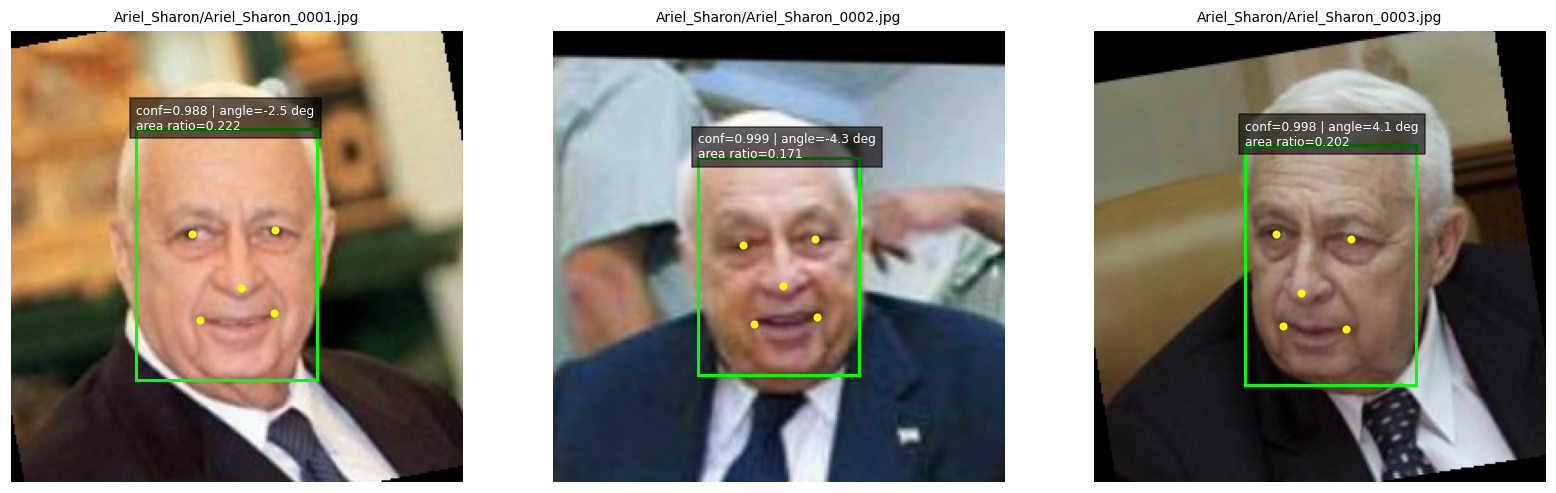

In [19]:
import io
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image as DisplayImage

example_paths = mtcnn_detections["path"].drop_duplicates().head(3).tolist()
if not example_paths:
    print("No detected faces to display. Inspect mtcnn_images for no-face images or errors.")
else:
    fig, axes = plt.subplots(1, len(example_paths), figsize=(6 * len(example_paths), 6), squeeze=False)
    for ax, relative_path in zip(axes[0], example_paths):
        with Image.open(MTCNN_DATA / relative_path) as source:
            ax.imshow(ImageOps.exif_transpose(source).convert("RGB"))
        for _, face in mtcnn_detections.loc[mtcnn_detections["path"] == relative_path].iterrows():
            ax.add_patch(Rectangle((face["clipped_x"], face["clipped_y"]),
                                   face["clipped_width"], face["clipped_height"],
                                   fill=False, edgecolor="lime", linewidth=2))
            angle = f"{face['eye_angle_degrees']:.1f} deg" if face["eye_angle_available"] else "missing eyes"
            ax.text(face["clipped_x"], face["clipped_y"],
                    f"conf={face['confidence']:.3f} | angle={angle}\narea ratio={face['face_to_image_area_ratio']:.3f}",
                    fontsize=8, color="white", bbox={"facecolor": "black", "alpha": 0.6})
            for name in LANDMARKS:
                if face[f"{name}_available"]:
                    ax.scatter(face[f"{name}_x"], face[f"{name}_y"], s=18, color="yellow")
        ax.set_title(relative_path, fontsize=9)
        ax.axis("off")
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(DisplayImage(data=buffer.getvalue()))